In [2]:
from pathlib import Path

import geopandas as gpd

caminho_pb = Path("../dados/brutos/bairros/prefeitura_bairro.gpkg")

pref_bairro = gpd.read_file(
    caminho_pb,
    layer="prefeituras_bairro_a",
).to_crs(epsg=31984)

limite_salvador = pref_bairro.geometry.union_all()

# Cria a margem no CRS projetado, em que a unidade é o metro.
margem_m = 2_000
area_busca = limite_salvador.buffer(margem_m)

# Prepara o polígono em longitude e latitude para a próxima etapa.
area_busca_wgs84 = gpd.GeoSeries(
    [area_busca], crs="EPSG:31984"
).to_crs(epsg=4326).iloc[0]

print(f"Área do recorte: {limite_salvador.area / 1_000_000:,.2f} km²")
print(f"Área de busca com margem: {area_busca.area / 1_000_000:,.2f} km²")
print("Tipo da área de busca:", area_busca_wgs84.geom_type)
print("Geometria válida:", area_busca_wgs84.is_valid)

Área do recorte: 304.11 km²
Área de busca com margem: 613.35 km²
Tipo da área de busca: MultiPolygon
Geometria válida: True


In [3]:
import osmnx as ox

caminho_rede = Path(
    "../dados/processados/rede_caminhada/rede_salvador_margem_2km.graphml"
)
caminho_rede.parent.mkdir(parents=True, exist_ok=True)

if caminho_rede.exists():
    rede_salvador = ox.io.load_graphml(caminho_rede)
    print("Rede carregada do arquivo.")
else:
    rede_salvador = ox.graph.graph_from_polygon(
        area_busca_wgs84,
        network_type="walk",
        simplify=True,
        retain_all=True,
    )
    ox.io.save_graphml(rede_salvador, filepath=caminho_rede)
    print("Rede baixada e salva.")

print("Nós:", rede_salvador.number_of_nodes())
print("Arestas:", rede_salvador.number_of_edges())
print("CRS:", rede_salvador.graph["crs"])

Rede carregada do arquivo.
Nós: 57156
Arestas: 149876
CRS: epsg:4326


In [4]:
import networkx as nx

tamanhos = sorted(
    (len(componente) for componente in nx.weakly_connected_components(rede_salvador)),
    reverse=True,
)

print("Componentes:", len(tamanhos))
print("Nós nos 5 maiores componentes:", tamanhos[:5])
print("Nós fora do maior componente:", sum(tamanhos[1:]))
print(f"Nós no maior componente: {100 * tamanhos[0] / sum(tamanhos):.2f}%")

Componentes: 385
Nós nos 5 maiores componentes: [55494, 159, 158, 130, 116]
Nós fora do maior componente: 1662
Nós no maior componente: 97.09%


In [5]:
unidades = gpd.read_file(
    "../dados/brutos/saude/saude.gpkg",
    layer="sau_p",
).to_crs(epsg=31984)

unidades["tipo_tratado"] = (
    unidades["tipo_1"].astype("string").str.strip().str.upper()
)

unidades_busca = unidades.loc[
    unidades["tipo_tratado"].isin(["UBS", "USF"])
    & unidades.geometry.intersects(area_busca)
].copy()

rede_utm = ox.projection.project_graph(rede_salvador, to_crs="EPSG:31984")

arestas, distancias = ox.distance.nearest_edges(
    rede_utm,
    X=unidades_busca.geometry.x.to_numpy(),
    Y=unidades_busca.geometry.y.to_numpy(),
    return_dist=True,
)

# Numere os componentes por tamanho: 1 é o maior.
componentes = sorted(
    nx.weakly_connected_components(rede_utm), key=len, reverse=True
)
componente_por_no = {
    no: numero
    for numero, componente in enumerate(componentes, start=1)
    for no in componente
}

unidades_busca["dist_aresta_m"] = distancias
unidades_busca["componente"] = [componente_por_no[u] for u, v, chave in arestas]

print("Unidades na área de busca:", len(unidades_busca))
print("Componentes com unidades:", unidades_busca["componente"].nunique())
print("Unidades por componente:")
print(unidades_busca["componente"].value_counts().sort_index())
print(f"Maior distância à aresta: {unidades_busca['dist_aresta_m'].max():.2f} m")

Unidades na área de busca: 142
Componentes com unidades: 4
Unidades por componente:
componente
1    139
4      1
5      1
6      1
Name: count, dtype: int64
Maior distância à aresta: 42.87 m


In [6]:
grade_pop_salvador = gpd.read_file(
    "../dados/processados/grade_h3/grade_h3_r10_pop_salvador.gpkg",
    layer="grade_h3_r10_pop_salvador",
).to_crs(epsg=31984)

pontos_grade = grade_pop_salvador[
    ["h3_id", "pop_estimada", "geometry"]
].copy()
pontos_grade["geometry"] = pontos_grade.geometry.representative_point()

arestas_grade, distancias_grade = ox.distance.nearest_edges(
    rede_utm,
    X=pontos_grade.geometry.x.to_numpy(),
    Y=pontos_grade.geometry.y.to_numpy(),
    return_dist=True,
)

pontos_grade["aresta_rede"] = [tuple(aresta) for aresta in arestas_grade]
pontos_grade["dist_aresta_m"] = distancias_grade
pontos_grade["componente"] = [
    componente_por_no[u] for u, v, chave in arestas_grade
]

sem_unidade = ~pontos_grade["componente"].isin(unidades_busca["componente"])

print("Células associadas à rede:", len(pontos_grade))
print("Células em componentes sem unidade:", sem_unidade.sum())
print(f"População estimada nessas células: {pontos_grade.loc[sem_unidade, 'pop_estimada'].sum():,.2f}")
print("\nDistância dos pontos à aresta (m):")
print(pontos_grade["dist_aresta_m"].describe().round(2))

Células associadas à rede: 18317
Células em componentes sem unidade: 404
População estimada nessas células: 11,517.48

Distância dos pontos à aresta (m):
count    18317.00
mean        72.65
std        125.45
min          0.00
25%          9.40
50%         24.66
75%         73.98
max       1555.14
Name: dist_aresta_m, dtype: float64


In [7]:
for limite_m in [100, 250, 500]:
    longe = pontos_grade["dist_aresta_m"] > limite_m
    pop_longe = pontos_grade.loc[longe, "pop_estimada"].sum()
    print(
        f"Acima de {limite_m:>3} m: {longe.sum():>5} células | "
        f"{pop_longe:,.2f} pessoas estimadas"
    )

print("\n10 maiores afastamentos entre células com população estimada > 0:")
display(
    pontos_grade.loc[
        pontos_grade["pop_estimada"] > 0,
        ["h3_id", "pop_estimada", "dist_aresta_m", "componente"],
    ]
    .nlargest(10, "dist_aresta_m")
    .round(2)
)

Acima de 100 m:  3640 células | 38,664.90 pessoas estimadas
Acima de 250 m:  1420 células | 4,886.62 pessoas estimadas
Acima de 500 m:   317 células | 203.63 pessoas estimadas

10 maiores afastamentos entre células com população estimada > 0:


,h3_id,pop_estimada,dist_aresta_m,componente
17405,8a8116a41baffff,0.00,1555.14,5
17438,8a8116a41a37fff,0.00,1505.31,72
17461,8a8116a41a07fff,0.00,1474.07,72
17383,8a8116a41ba7fff,0.00,1468.21,5
17441,8a8116a41b8ffff,0.01,1460.45,72
17428,8a8116a41b87fff,0.01,1446.52,5
17465,8a8116a41a17fff,0.01,1404.37,72
17444,8a8116a41b9ffff,0.01,1381.35,72
17386,8a8116a41bb7fff,0.00,1351.56,5
17498,8a8116a41a1ffff,0.00,1349.38,72


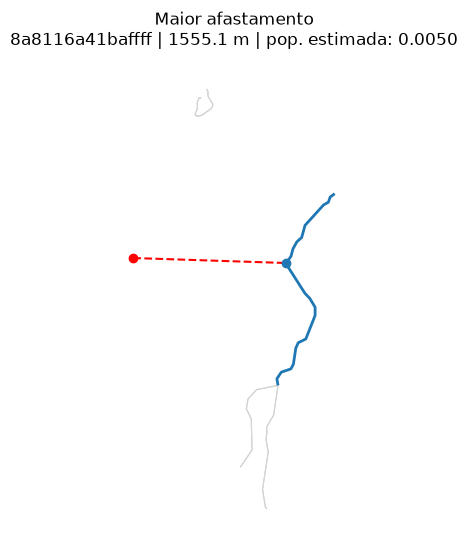

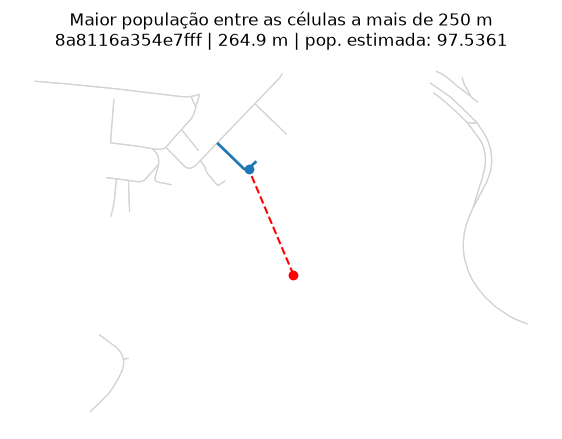

In [8]:
import matplotlib.pyplot as plt

arestas_mapa = ox.graph_to_gdfs(rede_utm, nodes=False)

casos = [
    ("Maior afastamento", pontos_grade.nlargest(1, "dist_aresta_m").iloc[0]),
    (
        "Maior população entre as células a mais de 250 m",
        pontos_grade.loc[pontos_grade["dist_aresta_m"] > 250]
        .nlargest(1, "pop_estimada").iloc[0],
    ),
]

for titulo, caso in casos:
    ponto = caso.geometry
    aresta = arestas_mapa.loc[caso["aresta_rede"], "geometry"]
    entrada = aresta.interpolate(aresta.project(ponto))

    x_min, y_min, x_max, y_max = ponto.buffer(
        caso["dist_aresta_m"] + 150
    ).bounds
    entorno = arestas_mapa.cx[x_min:x_max, y_min:y_max]

    fig, ax = plt.subplots(figsize=(7, 6))
    entorno.plot(ax=ax, color="lightgray", linewidth=0.8)
    gpd.GeoSeries([aresta], crs=rede_utm.graph["crs"]).plot(
        ax=ax, color="tab:blue", linewidth=2
    )
    ax.plot([ponto.x, entrada.x], [ponto.y, entrada.y], "r--")
    ax.scatter(ponto.x, ponto.y, color="red", zorder=3)
    ax.scatter(entrada.x, entrada.y, color="tab:blue", zorder=3)
    ax.set_title(
        f"{titulo}\n{caso['h3_id']} | {caso['dist_aresta_m']:.1f} m | "
        f"pop. estimada: {caso['pop_estimada']:.4f}"
    )
    ax.set_axis_off()
    plt.show()

In [9]:
pontos_grade["ligacao_longa"] = pontos_grade["dist_aresta_m"] > 250
unidades_busca["aresta_rede"] = [tuple(aresta) for aresta in arestas]

print("Células com ligação longa:", pontos_grade["ligacao_longa"].sum())
print("Unidades com aresta registrada:", unidades_busca["aresta_rede"].notna().sum())

Células com ligação longa: 1420
Unidades com aresta registrada: 142


In [10]:
from shapely.geometry import Point

def medir_entrada(registro):
    u, v, chave = registro["aresta_rede"]
    linha = arestas_mapa.loc[(u, v, chave), "geometry"]
    ponto = registro.geometry

    no_u = Point(rede_utm.nodes[u]["x"], rede_utm.nodes[u]["y"])
    inicio = Point(linha.coords[0])
    fim = Point(linha.coords[-1])

    posicao = linha.project(ponto)
    entrada = linha.interpolate(posicao)
    fracao = posicao / linha.length

    if fim.distance(no_u) < inicio.distance(no_u):
        fracao = 1 - fracao

    comprimento_m = rede_utm[u][v][chave]["length"]
    parcial_u_m = fracao * comprimento_m
    parcial_v_m = comprimento_m - parcial_u_m

    return {
        "ligacao_m": ponto.distance(entrada),
        "parcial_u_m": parcial_u_m,
        "parcial_v_m": parcial_v_m,
        "comprimento_m": comprimento_m,
        "soma_parciais_m": parcial_u_m + parcial_v_m,
    }

# Para este teste arestas com extremidades distintas.
for rotulo, tabela in [("Célula", pontos_grade), ("Unidade", unidades_busca)]:
    teste = tabela.loc[tabela["aresta_rede"].map(lambda a: a[0] != a[1])].iloc[0]
    print(f"\n{rotulo} — aresta {teste['aresta_rede']}")
    for nome, valor in medir_entrada(teste).items():
        print(f"{nome}: {valor:.2f} m")
    print(f"Distância registrada à aresta: {teste['dist_aresta_m']:.2f} m")


Célula — aresta (7277027775, 12994295972, 0)
ligacao_m: 31.95 m
parcial_u_m: 322.98 m
parcial_v_m: 437.03 m
comprimento_m: 760.01 m
soma_parciais_m: 760.01 m
Distância registrada à aresta: 31.95 m

Unidade — aresta (7590718588, 7590718594, 0)
ligacao_m: 9.26 m
parcial_u_m: 17.14 m
parcial_v_m: 1.69 m
comprimento_m: 18.83 m
soma_parciais_m: 18.83 m
Distância registrada à aresta: 9.26 m


In [11]:
def diagnosticar_sentido(aresta):
    u, v, chave = aresta

    if u == v:
        return "laço"

    linha = arestas_mapa.loc[(u, v, chave), "geometry"]
    reversas = rede_utm.get_edge_data(v, u, default={})

    for chave_reversa in reversas:
        linha_reversa = arestas_mapa.loc[(v, u, chave_reversa), "geometry"]
        if linha.equals(linha_reversa):
            return "reversa no mesmo trecho"

    return "sem reversa confirmada"


for rotulo, tabela in [("Células", pontos_grade), ("Unidades", unidades_busca)]:
    tabela["sentido_aresta"] = tabela["aresta_rede"].map(diagnosticar_sentido)
    print(f"\n{rotulo}:")
    print(tabela["sentido_aresta"].value_counts().to_string())


Células:
sentido_aresta
reversa no mesmo trecho    18066
laço                         251

Unidades:
sentido_aresta
reversa no mesmo trecho    141
laço                         1


In [12]:
from shapely.geometry import LineString

def laco_tem_reversa(aresta):
    u, v, chave = aresta
    linha = arestas_mapa.loc[(u, v, chave), "geometry"]
    linha_invertida = LineString(list(linha.coords)[::-1])

    return any(
        outra_chave != chave
        and arestas_mapa.loc[(u, v, outra_chave), "geometry"]
        .equals_exact(linha_invertida, tolerance=0.01)
        for outra_chave in rede_utm[u][v]
    )

for rotulo, tabela in [("Células", pontos_grade), ("Unidades", unidades_busca)]:
    lacos = tabela.loc[tabela["sentido_aresta"].eq("laço")].copy()
    lacos["reversa_confirmada"] = lacos["aresta_rede"].map(laco_tem_reversa)

    print(f"\n{rotulo} em laços: {len(lacos)}")
    print("Com reversa confirmada:", lacos["reversa_confirmada"].sum())
    print("Sem reversa confirmada:", (~lacos["reversa_confirmada"]).sum())


Células em laços: 251
Com reversa confirmada: 251
Sem reversa confirmada: 0

Unidades em laços: 1
Com reversa confirmada: 1
Sem reversa confirmada: 0


In [13]:
import numpy as np
import pandas as pd

colunas_entrada = [
    "ligacao_m",
    "parcial_u_m",
    "parcial_v_m",
    "comprimento_m",
    "soma_parciais_m",
]

for rotulo, tabela in [("Células", pontos_grade), ("Unidades", unidades_busca)]:
    medidas = pd.DataFrame(
        [medir_entrada(registro) for _, registro in tabela.iterrows()],
        columns=colunas_entrada,
    )
    tabela[colunas_entrada] = medidas.to_numpy()

    ligacao_ok = np.isclose(
        tabela["ligacao_m"], tabela["dist_aresta_m"], atol=0.01, rtol=0
    )
    parciais_ok = np.isclose(
        tabela["soma_parciais_m"], tabela["comprimento_m"], atol=0.01, rtol=0
    )
    invalidas = (
        ~np.isfinite(medidas.to_numpy()).all(axis=1)
        | (medidas.to_numpy() < 0).any(axis=1)
    )

    print(f"\n{rotulo}: {len(tabela)}")
    print("Medidas inválidas:", invalidas.sum())
    print("Divergências na ligação:", (~ligacao_ok).sum())
    print("Divergências na soma das parciais:", (~parciais_ok).sum())


Células: 18317
Medidas inválidas: 0
Divergências na ligação: 0
Divergências na soma das parciais: 0

Unidades: 142
Medidas inválidas: 0
Divergências na ligação: 0
Divergências na soma das parciais: 0


In [14]:
custo_por_no = {}

for _, unidade in unidades_busca.iterrows():
    u, v, _ = unidade["aresta_rede"]

    for no, parcial_m in [
        (u, unidade["parcial_u_m"]),
        (v, unidade["parcial_v_m"]),
    ]:
        custo_m = parcial_m + unidade["ligacao_m"]
        custo_por_no[no] = min(custo_por_no.get(no, float("inf")), custo_m)

rede_invertida = rede_utm.reverse(copy=True)
destino_virtual = "__ubs_usf__"

for no, custo_m in custo_por_no.items():
    rede_invertida.add_edge(destino_virtual, no, length=custo_m)

dist_no_ate_unidade_m = nx.single_source_dijkstra_path_length(
    rede_invertida,
    source=destino_virtual,
    weight="length",
)
dist_no_ate_unidade_m.pop(destino_virtual)

print("Nós de entrada das unidades:", len(custo_por_no))
print("Nós com rota até uma UBS/USF:", len(dist_no_ate_unidade_m))
print(
    "Nós sem rota no modelo:",
    rede_utm.number_of_nodes() - len(dist_no_ate_unidade_m),
)

Nós de entrada das unidades: 281
Nós com rota até uma UBS/USF: 55810
Nós sem rota no modelo: 1346


In [15]:
def distancia_via_extremidades(celula):
    u, v, _ = celula["aresta_rede"]

    via_u = celula["parcial_u_m"] + dist_no_ate_unidade_m.get(u, np.inf)
    via_v = celula["parcial_v_m"] + dist_no_ate_unidade_m.get(v, np.inf)

    return celula["ligacao_m"] + min(via_u, via_v)


pontos_grade["dist_via_extremidades_m"] = pontos_grade.apply(
    distancia_via_extremidades, axis=1
)

# Sem rota fica como NaN, para não entrar nas contas como distância zero.
pontos_grade["dist_via_extremidades_m"] = (
    pontos_grade["dist_via_extremidades_m"].replace(np.inf, np.nan)
)

sem_rota = pontos_grade["dist_via_extremidades_m"].isna()

print("Células com rota pelas extremidades:", (~sem_rota).sum())
print("Células sem rota:", sem_rota.sum())
print(
    f"População estimada sem rota: "
    f"{pontos_grade.loc[sem_rota, 'pop_estimada'].sum():,.2f}"
)

Células com rota pelas extremidades: 17913
Células sem rota: 404
População estimada sem rota: 11,517.48


In [16]:
from collections import defaultdict

unidades_por_par = defaultdict(list)

for _, unidade in unidades_busca.iterrows():
    u, v, _ = unidade["aresta_rede"]
    unidades_por_par[frozenset((u, v))].append(unidade)


def distancia_direta_mesmo_trecho(celula):
    u, v, chave = celula["aresta_rede"]
    candidatas = unidades_por_par.get(frozenset((u, v)), ())

    if not candidatas:
        return np.nan

    linha = arestas_mapa.loc[(u, v, chave), "geometry"]
    pos_celula = linha.project(celula.geometry)
    melhor_m = np.inf

    for unidade in candidatas:
        linha_unidade = arestas_mapa.loc[unidade["aresta_rede"], "geometry"]
        if not linha.equals(linha_unidade):
            continue

        # Projete os dois pontos na mesma linha para usar a mesma orientação.
        pos_unidade = linha.project(unidade.geometry)
        trecho_m = abs(pos_celula - pos_unidade)

        if u == v:
            # No laço, também é possível caminhar pelo outro lado.
            trecho_m = min(trecho_m, linha.length - trecho_m)

        trecho_m *= celula["comprimento_m"] / linha.length
        total_m = celula["ligacao_m"] + trecho_m + unidade["ligacao_m"]
        melhor_m = min(melhor_m, total_m)

    return melhor_m if np.isfinite(melhor_m) else np.nan


pontos_grade["dist_direta_m"] = pontos_grade.apply(
    distancia_direta_mesmo_trecho, axis=1
)

pontos_grade["dist_final_m"] = pontos_grade[
    ["dist_via_extremidades_m", "dist_direta_m"]
].min(axis=1)

reduziu = (
    pontos_grade["dist_direta_m"]
    < pontos_grade["dist_via_extremidades_m"] - 0.01
)

print("Células com opção direta:", pontos_grade["dist_direta_m"].notna().sum())
print("Células com distância reduzida:", reduziu.sum())
print("Células sem rota após a comparação:", pontos_grade["dist_final_m"].isna().sum())

Células com opção direta: 83
Células com distância reduzida: 80
Células sem rota após a comparação: 404


In [17]:
velocidade_m_min = 4_000 / 60
pontos_grade["tempo_min"] = pontos_grade["dist_final_m"] / velocidade_m_min

pop_total = pontos_grade["pop_estimada"].sum()

for limite_min in [5, 10, 15, 20]:
    cobertas = pontos_grade["tempo_min"].le(limite_min)
    pop_coberta = pontos_grade.loc[cobertas, "pop_estimada"].sum()

    print(
        f"Até {limite_min:>2} min: {cobertas.sum():>5} células | "
        f"{pop_coberta:,.0f} pessoas estimadas | "
        f"{100 * pop_coberta / pop_total:.2f}%"
    )

acima_20 = pontos_grade["tempo_min"].gt(20)
sem_rota = pontos_grade["tempo_min"].isna()

for rotulo, filtro in [
    ("Com rota acima de 20 min", acima_20),
    ("Sem rota no modelo", sem_rota),
]:
    pop_grupo = pontos_grade.loc[filtro, "pop_estimada"].sum()
    print(f"{rotulo}: {filtro.sum()} células | {pop_grupo:,.0f} pessoas estimadas")

Até  5 min:   922 células | 277,023 pessoas estimadas | 11.49%
Até 10 min:  3454 células | 956,678 pessoas estimadas | 39.69%
Até 15 min:  6298 células | 1,558,909 pessoas estimadas | 64.68%
Até 20 min:  8687 células | 1,923,306 pessoas estimadas | 79.80%
Com rota acima de 20 min: 9226 células | 475,408 pessoas estimadas
Sem rota no modelo: 404 células | 11,517 pessoas estimadas


In [18]:
ate_20 = pontos_grade["tempo_min"].le(20)
cobertura_sinalizada = ate_20 & pontos_grade["ligacao_longa"]

pop_ate_20 = pontos_grade.loc[ate_20, "pop_estimada"].sum()
pop_sinalizada = pontos_grade.loc[cobertura_sinalizada, "pop_estimada"].sum()

pct_original = 100 * pop_ate_20 / pop_total
pct_conservador = 100 * (pop_ate_20 - pop_sinalizada) / pop_total

print("Células cobertas com ligação acima de 250 m:", cobertura_sinalizada.sum())
print(f"População estimada nessas células: {pop_sinalizada:,.2f}")
print(f"Cobertura original até 20 min: {pct_original:.2f}%")
print(f"Cobertura no cenário conservador: {pct_conservador:.2f}%")
print(f"Queda: {pct_original - pct_conservador:.3f} ponto percentual")

Células cobertas com ligação acima de 250 m: 133
População estimada nessas células: 776.89
Cobertura original até 20 min: 79.80%
Cobertura no cenário conservador: 79.77%
Queda: 0.032 ponto percentual


In [19]:
faixas = [
    "Até 5 min",
    "Mais de 5 a 10 min",
    "Mais de 10 a 15 min",
    "Mais de 15 a 20 min",
    "Mais de 20 min",
]

pontos_grade["faixa_caminhada"] = (
    pd.cut(
        pontos_grade["tempo_min"],
        bins=[0, 5, 10, 15, 20, np.inf],
        labels=faixas,
        include_lowest=True,
    )
    .cat.add_categories(["Sem rota no modelo"])
    .fillna("Sem rota no modelo")
    .astype("string")
)

colunas_resultado = [
    "h3_id", "dist_aresta_m", "ligacao_longa",
    "dist_final_m", "tempo_min", "faixa_caminhada",
]

grade_acesso_salvador = grade_pop_salvador.merge(
    pontos_grade[colunas_resultado],
    on="h3_id",
    how="left",
    validate="one_to_one",
)

assert grade_acesso_salvador["faixa_caminhada"].notna().all()

saida_acesso = Path(
    "../dados/processados/acessibilidade/grade_h3_r10_acesso_salvador.gpkg"
)
saida_acesso.parent.mkdir(parents=True, exist_ok=True)

grade_acesso_salvador.to_file(
    saida_acesso,
    layer="acesso_ubs_usf_salvador",
    driver="GPKG",
    index=False,
)

print("Células:", len(grade_acesso_salvador))
print(grade_acesso_salvador["faixa_caminhada"].value_counts().to_string())

Células: 18317
faixa_caminhada
Mais de 20 min         9226
Mais de 10 a 15 min    2844
Mais de 5 a 10 min     2532
Mais de 15 a 20 min    2389
Até 5 min               922
Sem rota no modelo      404


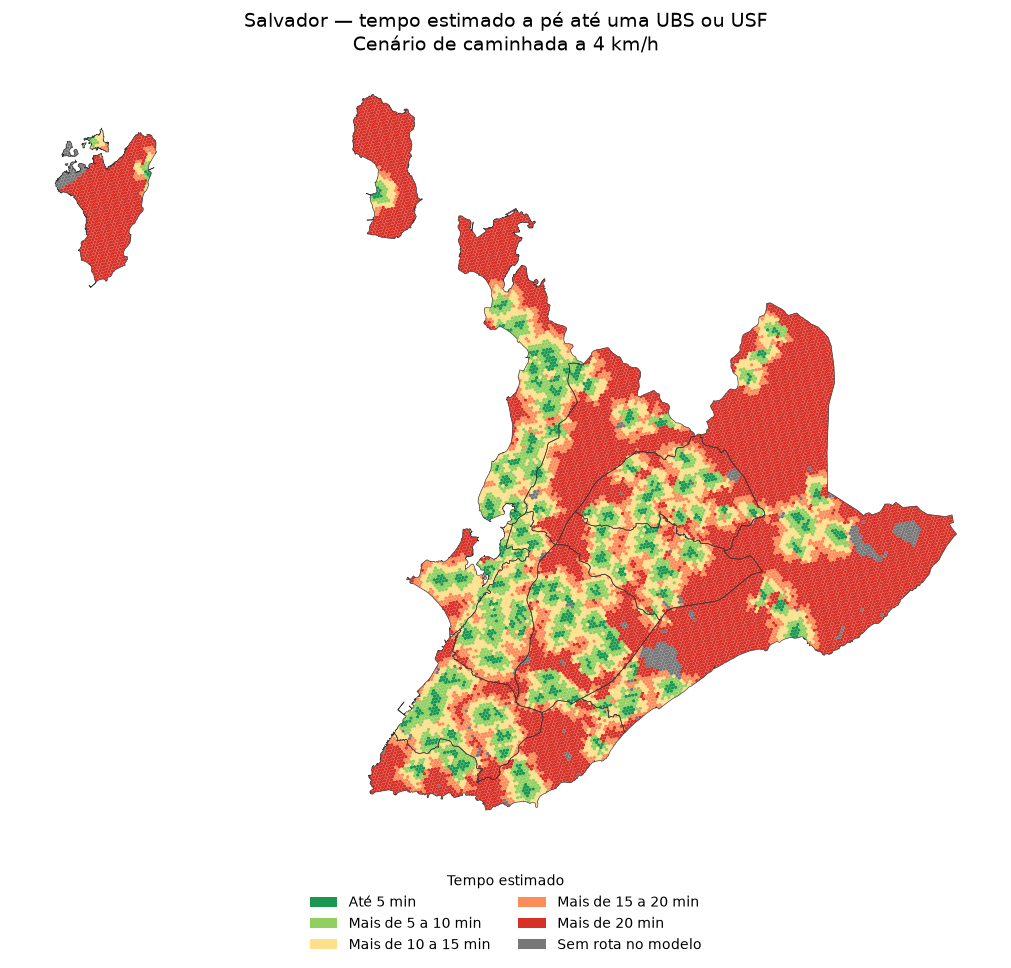

In [20]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

cores = {
    "Até 5 min": "#1a9850",
    "Mais de 5 a 10 min": "#91cf60",
    "Mais de 10 a 15 min": "#fee08b",
    "Mais de 15 a 20 min": "#fc8d59",
    "Mais de 20 min": "#d73027",
    "Sem rota no modelo": "#777777",
}

fig, ax = plt.subplots(figsize=(10, 11), layout="constrained")

grade_acesso_salvador.plot(
    ax=ax,
    color=grade_acesso_salvador["faixa_caminhada"].map(cores),
    linewidth=0,
)

pref_bairro.boundary.plot(ax=ax, color="#333333", linewidth=0.45)

ax.set_title(
    "Salvador — tempo estimado a pé até uma UBS ou USF\n"
    "Cenário de caminhada a 4 km/h",
    fontsize=14,
)
ax.legend(
    handles=[Patch(facecolor=cor, label=faixa) for faixa, cor in cores.items()],
    title="Tempo estimado",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.02),
    ncol=2,
    frameon=False,
)
ax.set_axis_off()

saida_mapa = Path("../resultados/mapas/acesso_ubs_usf_salvador.png")
saida_mapa.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(saida_mapa, dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

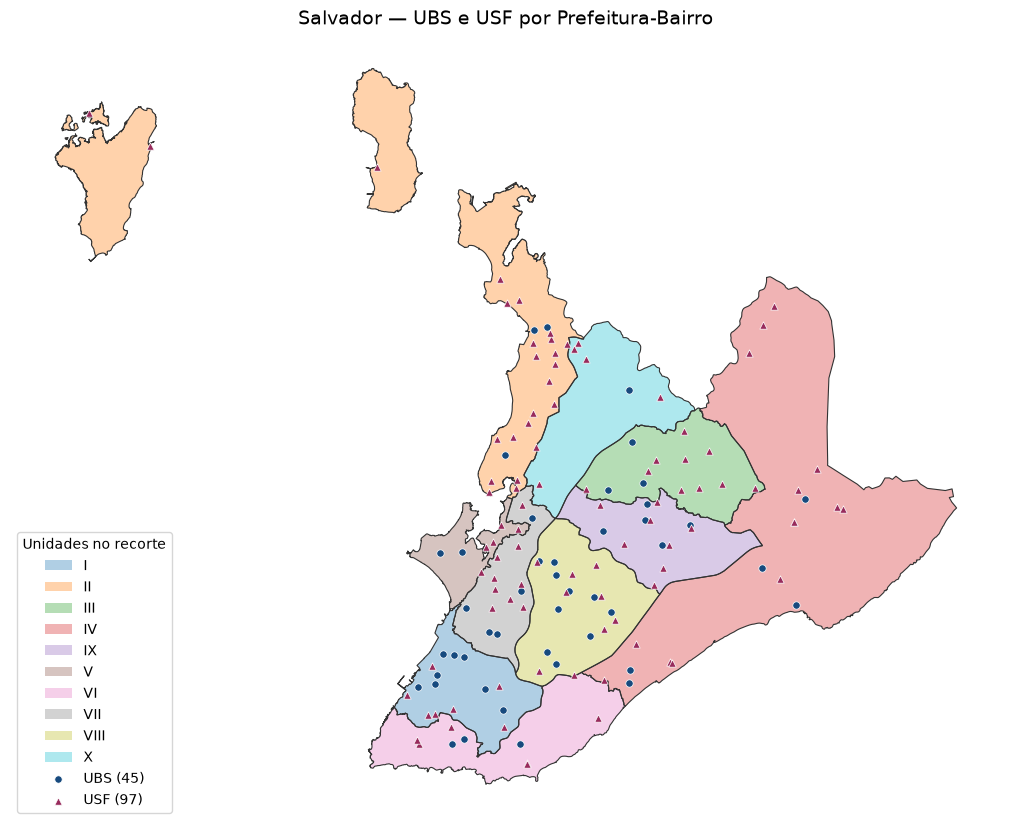

In [23]:
import matplotlib.patheffects as pe
# Mostra apenas as unidades dentro do recorte municipal sem a margem de 2 km.
unidades_mapa = unidades_busca.loc[
    unidades_busca.geometry.intersects(limite_salvador)
].copy()

fig, ax = plt.subplots(figsize=(10, 10), layout="constrained")

pref_bairro.plot(
    ax=ax,
    column="COD_PBR",
    categorical=True,
    cmap="tab10",
    alpha=0.35,
)
pref_bairro.boundary.plot(ax=ax, color="#333333", linewidth=0.8)

#Prefeituras-Bairro no mapa.
# for _, regiao in pref_bairro.iterrows():
#     ponto = regiao.geometry.representative_point()
#     ax.text(
#         ponto.x, ponto.y, regiao["COD_PBR"],
#         ha="center", va="center", fontsize=10, fontweight="bold",
#         path_effects=[pe.withStroke(linewidth=3, foreground="white")],
#         zorder=4,
#     )

for tipo, marcador, cor in [
    ("UBS", "o", "#174A7E"),
    ("USF", "^", "#982B5C"),
]:
    pontos = unidades_mapa.loc[unidades_mapa["tipo_tratado"].eq(tipo)]
    if not pontos.empty:
        ax.scatter(
            pontos.geometry.x, pontos.geometry.y,
            marker=marcador, s=28, c=cor,
            edgecolors="white", linewidths=0.5,
            label=f"{tipo} ({len(pontos)})", zorder=5,
        )

ax.set_title("Salvador — UBS e USF por Prefeitura-Bairro", fontsize=14)
ax.legend(loc="lower left", title="Unidades no recorte")
ax.set_axis_off()
plt.show()

In [24]:

grade_distancia = gpd.read_file(
    "../dados/processados/acessibilidade/grade_h3_r10_acesso_salvador.gpkg",
    layer="acesso_ubs_usf_salvador",
    ignore_geometry=True,
)

colunas = ["h3_id", "dist_final_m", "pop_estimada", "faixa_caminhada"]
faltantes = [coluna for coluna in colunas if coluna not in grade_distancia]
assert not faltantes, f"Colunas ausentes: {faltantes}"

distancia = grade_distancia["dist_final_m"]
populacao = grade_distancia["pop_estimada"]

sem_rota = distancia.isna()
faixa_sem_rota = grade_distancia["faixa_caminhada"].eq("Sem rota no modelo")
distancia_invalida = distancia.notna() & (~np.isfinite(distancia) | distancia.lt(0))
populacao_invalida = ~np.isfinite(populacao) | populacao.lt(0)

print("Células:", len(grade_distancia))
print("IDs ausentes:", grade_distancia["h3_id"].isna().sum())
print("IDs duplicados:", grade_distancia["h3_id"].duplicated().sum())
print("Distâncias inválidas:", distancia_invalida.sum())
print("Pesos populacionais inválidos:", populacao_invalida.sum())
print("Divergências na classificação sem rota:", sem_rota.ne(faixa_sem_rota).sum())
print("Células sem rota:", sem_rota.sum())
print(f"População estimada sem rota: {populacao[sem_rota].sum():,.2f}")
print(f"População estimada total: {populacao.sum():,.2f}")

Células: 18317
IDs ausentes: 0
IDs duplicados: 0
Distâncias inválidas: 0
Pesos populacionais inválidos: 0
Divergências na classificação sem rota: 0
Células sem rota: 404
População estimada sem rota: 11,517.48
População estimada total: 2,410,231.79


In [25]:
def resumir_distancias(tabela, coluna_pop):
    com_rota = tabela.loc[tabela["dist_final_m"].notna()]
    ponderadas = com_rota.loc[com_rota[coluna_pop].gt(0)].sort_values("dist_final_m")

    dist = ponderadas["dist_final_m"].to_numpy(dtype=float)
    pesos = ponderadas[coluna_pop].to_numpy(dtype=float)
    acumulado = pesos.cumsum()
    pop_com_rota = acumulado[-1]

    def percentil(q):
        posicao = np.searchsorted(acumulado, q * pop_com_rota, side="left")
        return dist[posicao]

    return {
        "media_ponderada_m": np.average(dist, weights=pesos),
        "mediana_ponderada_m": percentil(0.50),
        "p75_ponderado_m": percentil(0.75),
        "p90_ponderado_m": percentil(0.90),
        "maior_distancia_com_rota_m": com_rota["dist_final_m"].max(),
    }


resumo_dist_salvador = resumir_distancias(grade_distancia, "pop_estimada")

for indicador, valor in resumo_dist_salvador.items():
    print(f"{indicador}: {valor:,.2f} m")

print("\nCélula com a maior distância com rota:")
print(
    grade_distancia.nlargest(1, "dist_final_m")[
        ["h3_id", "dist_final_m", "pop_estimada"]
    ].to_string(index=False)
)

media_ponderada_m: 949.34 m
mediana_ponderada_m: 789.96 m
p75_ponderado_m: 1,197.47 m
p90_ponderado_m: 1,738.64 m
maior_distancia_com_rota_m: 7,769.46 m

Célula com a maior distância com rota:
          h3_id  dist_final_m  pop_estimada
8a8116b9c2f7fff   7769.457518           0.0


In [26]:

limite_20_min_m = 4_000 * 20 / 60

rotulos = [
    "Até 500 m",
    "Acima de 500 m até 1 km",
    "Acima de 1 km até ≈ 1,33 km",
    "Acima de ≈ 1,33 km",
]

grade_distancia["faixa_distancia"] = (
    pd.cut(
        grade_distancia["dist_final_m"],
        bins=[0, 500, 1_000, limite_20_min_m, np.inf],
        labels=rotulos,
        include_lowest=True,
    )
    .cat.add_categories(["Sem rota no modelo"])
    .fillna("Sem rota no modelo")
)

faixas_salvador = (
    grade_distancia.groupby("faixa_distancia", observed=False)
    .agg(
        celulas=("h3_id", "size"),
        pop_estimada=("pop_estimada", "sum"),
    )
)

pop_total_municipal = grade_distancia["pop_estimada"].sum()
faixas_salvador["pct_pop"] = (
    100 * faixas_salvador["pop_estimada"] / pop_total_municipal
)

print(faixas_salvador.round(2).to_string())
print(f"\nSoma dos percentuais: {faixas_salvador['pct_pop'].sum():.2f}%")
print(f"Cobertura até ≈ 1,33 km: {faixas_salvador['pct_pop'].iloc[:3].sum():.2f}%")

                             celulas  pop_estimada  pct_pop
faixa_distancia                                            
Até 500 m                       2041     587128.26    24.36
Acima de 500 m até 1 km         4257     971780.91    40.32
Acima de 1 km até ≈ 1,33 km     2389     364396.78    15.12
Acima de ≈ 1,33 km              9226     475408.37    19.72
Sem rota no modelo               404      11517.48     0.48

Soma dos percentuais: 100.00%
Cobertura até ≈ 1,33 km: 79.80%


In [28]:
pop_h3_regioes = pd.read_csv(
    "../dados/processados/populacao/pop_h3_por_prefeitura_bairro.csv",
    dtype={"h3_id": "string", "COD_PBR": "string"},
)

distancias_pb = pop_h3_regioes.merge(
    grade_distancia[["h3_id", "dist_final_m", "faixa_distancia"]],
    on="h3_id",
    how="left",
    validate="many_to_one",
    indicator=True,
)

assert distancias_pb["_merge"].eq("both").all(), "Há IDs sem correspondência na grade."
assert distancias_pb["COD_PBR"].nunique() == 10, "Confira os códigos das regiões."
assert np.isclose(
    distancias_pb["pop_estimada_pb"].sum(),
    grade_distancia["pop_estimada"].sum(),
    atol=0.01,
    rtol=0,
), "A soma da população regional diverge da grade municipal."

resumo_dist_pb = pd.DataFrame([
    {
        "COD_PBR": codigo,
        "PREF_BAIRR": nome,
        **resumir_distancias(grupo, "pop_estimada_pb"),
    }
    for (codigo, nome), grupo in distancias_pb.groupby(["COD_PBR", "PREF_BAIRR"])
])

print(
    resumo_dist_pb.sort_values("mediana_ponderada_m")
    .round(2)
    .to_string(index=False)
)

COD_PBR                                       PREF_BAIRR  media_ponderada_m  mediana_ponderada_m  p75_ponderado_m  p90_ponderado_m  maior_distancia_com_rota_m
     II          Prefeitura-bairro II - Subúrbio / Ilhas             702.01               627.82           895.83          1190.89                     7289.68
    VII  Prefeitura-bairro VII - Liberdade / São Caetano             666.52               642.60           841.03          1053.38                     2557.20
   VIII Prefeitura-bairro VIII - Cabula / Tancredo Neves             795.22               688.40          1056.56          1441.98                     4384.08
      I            Prefeitura-bairro I - Centro / Brotas             823.43               774.80          1126.12          1372.78                     3535.24
      V               Prefeitura-bairro V - Cidade Baixa             830.94               786.37          1041.96          1390.89                     3051.37
     IX              Prefeitura-bairro IX -  P

In [29]:
faixas_pb = (
    distancias_pb.groupby(["COD_PBR", "faixa_distancia"], observed=False)
    ["pop_estimada_pb"]
    .sum()
    .reset_index()
)

faixas_pb["pop_total_pb"] = (
    faixas_pb.groupby("COD_PBR")["pop_estimada_pb"].transform("sum")
)
faixas_pb["pct_pop"] = (
    100 * faixas_pb["pop_estimada_pb"] / faixas_pb["pop_total_pb"]
)

ordem_faixas = rotulos + ["Sem rota no modelo"]

tabela_pct_pb = (
    faixas_pb.pivot(index="COD_PBR", columns="faixa_distancia", values="pct_pop")
    .reindex(columns=ordem_faixas)
)
tabela_pct_pb["Soma (%)"] = tabela_pct_pb.sum(axis=1)
tabela_pct_pb["Até ≈ 1,33 km (%)"] = tabela_pct_pb[rotulos[:3]].sum(axis=1)

print(tabela_pct_pb.round(2).to_string())

faixa_distancia  Até 500 m  Acima de 500 m até 1 km  Acima de 1 km até ≈ 1,33 km  Acima de ≈ 1,33 km  Sem rota no modelo  Soma (%)  Até ≈ 1,33 km (%)
COD_PBR                                                                                                                                              
I                    26.02                    42.09                        18.31               12.73                0.85     100.0              86.42
II                   36.27                    45.59                        11.63                6.50                0.01     100.0              93.50
III                  19.67                    42.05                        19.34               18.38                0.56     100.0              81.05
IV                   15.69                    29.26                        15.23               38.86                0.96     100.0              60.18
IX                   23.16                    42.00                        18.52               15.64

In [30]:
grade_poligonos = gpd.read_file(
    "../dados/processados/acessibilidade/grade_h3_r10_acesso_salvador.gpkg",
    layer="acesso_ubs_usf_salvador",
    columns=["h3_id", "dist_final_m"],
)

celulas_com_rota = grade_poligonos.loc[grade_poligonos["dist_final_m"].notna()]

celulas_por_territorio = gpd.overlay(
    celulas_com_rota,
    pref_bairro[["COD_PBR", "geometry"]].to_crs(grade_poligonos.crs),
    how="intersection",
    keep_geom_type=True,
)

# Uma célula só conta na região se tiver área dentro dela.
celulas_por_territorio = celulas_por_territorio.loc[
    celulas_por_territorio.geometry.area.gt(0)
]

maximo_territorial = (
    celulas_por_territorio.groupby("COD_PBR")["dist_final_m"]
    .max()
    .rename("maximo_territorial_m")
)

conferencia_maximos = resumo_dist_pb[
    ["COD_PBR", "maior_distancia_com_rota_m"]
].merge(
    maximo_territorial, on="COD_PBR", how="left", validate="one_to_one"
)

conferencia_maximos["diferenca_m"] = (
    conferencia_maximos["maximo_territorial_m"]
    - conferencia_maximos["maior_distancia_com_rota_m"]
)

print(conferencia_maximos.round(2).to_string(index=False))

COD_PBR  maior_distancia_com_rota_m  maximo_territorial_m  diferenca_m
      I                     3535.24               3535.24          0.0
     II                     7289.68               7289.68          0.0
    III                     4848.31               4848.31          0.0
     IV                     7769.46               7769.46          0.0
     IX                     5051.99               5051.99          0.0
      V                     3051.37               3051.37          0.0
     VI                     4384.08               4384.08          0.0
    VII                     2557.20               2557.20          0.0
   VIII                     4384.08               4384.08          0.0
      X                     4315.58               4315.58          0.0


In [31]:
p90_por_pb = resumo_dist_pb.set_index("COD_PBR")["p90_ponderado_m"]

casos = [
    ("Curta — Centro/Brotas", "I", distancias_pb["dist_final_m"].le(500)),
    ("Longa — Itapuã/Ipitanga", "IV", distancias_pb["dist_final_m"].ge(p90_por_pb["IV"])),
    ("Longa — Barra/Pituba", "VI", distancias_pb["dist_final_m"].ge(p90_por_pb["VI"])),
]

amostra_rotas = pd.concat([
    distancias_pb.loc[
        distancias_pb["COD_PBR"].eq(codigo)
        & filtro
        & distancias_pb["pop_estimada_pb"].gt(0),
        ["COD_PBR", "h3_id", "dist_final_m", "pop_estimada_pb"],
    ]
    .sort_values(["pop_estimada_pb", "h3_id"], ascending=[False, True])
    .head(1)
    .assign(caso=rotulo)
    for rotulo, codigo, filtro in casos
], ignore_index=True)

print(amostra_rotas.round(2).to_string(index=False))

COD_PBR           h3_id  dist_final_m  pop_estimada_pb                    caso
      I 8a8116b1d297fff        236.40           692.39   Curta — Centro/Brotas
     IV 8a8116aa48effff       3465.38           619.09 Longa — Itapuã/Ipitanga
     VI 8a8116b1c06ffff       2127.96           988.26    Longa — Barra/Pituba


In [70]:
#h3_teste = "8a8116aa48effff"

#h3_teste = "8a8116b1c06ffff" #Barra/Pituba
#h3_teste = "8a8116b0ea57fff"
h3_teste = "8a8116ae5a37fff"
celula = pontos_grade.loc[pontos_grade["h3_id"].eq(h3_teste)].iloc[0]

print(f"Distância salva: {celula['dist_final_m']:.2f} m")
print(f"Via extremidades: {celula['dist_via_extremidades_m']:.2f} m")
print(f"Opção direta no mesmo trecho: {celula['dist_direta_m']:.2f} m")
print(f"Ligação inicial à rede: {celula['ligacao_m']:.2f} m")

direta_m = celula["dist_direta_m"]
via_extremidades_m = celula["dist_via_extremidades_m"]

if pd.notna(direta_m) and (
    pd.isna(via_extremidades_m) or direta_m < via_extremidades_m
):
    print("A opção direta venceu. Vamos reconstruir o subtrecho da aresta.")
else:
    u, v, _ = celula["aresta_rede"]
    saidas = [(u, celula["parcial_u_m"]), (v, celula["parcial_v_m"])]
    no_saida, parcial_saida_m = min(
        saidas,
        key=lambda item: item[1] + dist_no_ate_unidade_m.get(item[0], np.inf),
    )

    custo_m, caminho_invertido = nx.single_source_dijkstra(
        rede_invertida, destino_virtual, target=no_saida, weight="length"
    )
    nos_rota = caminho_invertido[1:][::-1]  # Retira o nó virtual e volta ao sentido real.
    no_chegada = nos_rota[-1]

    destinos = []
    for _, unidade in unidades_busca.iterrows():
        a, b, _ = unidade["aresta_rede"]
        for no, parcial_m in [(a, unidade["parcial_u_m"]), (b, unidade["parcial_v_m"])]:
            if no == no_chegada:
                destinos.append((parcial_m + unidade["ligacao_m"], unidade["unidade"]))

    custo_chegada_m = min(custo for custo, nome in destinos)
    nomes = sorted({
        nome for custo, nome in destinos
        if np.isclose(custo, custo_chegada_m, atol=0.001, rtol=0)
    })

    reconstruida_m = celula["ligacao_m"] + parcial_saida_m + custo_m
    print("Unidade de destino:", " / ".join(nomes))
    print("Nós no percurso de rede:", len(nos_rota))
    print(f"Distância reconstruída: {reconstruida_m:.2f} m")
    print(f"Diferença em relação à distância salva: {reconstruida_m - celula['dist_final_m']:.6f} m")

Distância salva: 315.24 m
Via extremidades: 315.24 m
Opção direta no mesmo trecho: nan m
Ligação inicial à rede: 0.69 m
Unidade de destino: USF ILHA DE MARE
Nós no percurso de rede: 6
Distância reconstruída: 315.24 m
Diferença em relação à distância salva: 0.000000 m


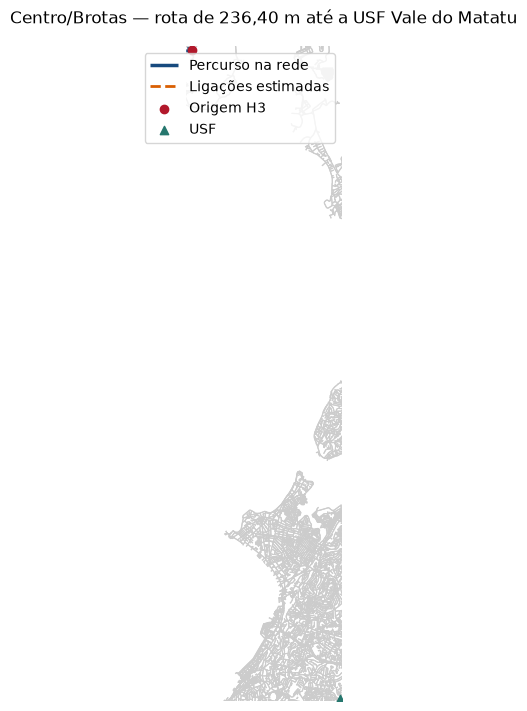

In [75]:
from shapely.ops import substring

destino = unidades_busca.loc[
    unidades_busca["unidade"].eq("USF VALE DO MATATU (OLGA DE ALAKETU)")
].iloc[0]

def trecho_ate_no(registro, no):
    linha = arestas_mapa.loc[registro["aresta_rede"], "geometry"]
    posicao = linha.project(registro.geometry)
    entrada = linha.interpolate(posicao)

    ponto_no = Point(rede_utm.nodes[no]["x"], rede_utm.nodes[no]["y"])
    extremo = (
        0 if Point(linha.coords[0]).distance(ponto_no)
        <= Point(linha.coords[-1]).distance(ponto_no)
        else linha.length
    )
    return entrada, substring(linha, posicao, extremo)

entrada, trecho_inicial = trecho_ate_no(celula, no_saida)
saida, trecho_final = trecho_ate_no(destino, no_chegada)

trechos = [trecho_inicial]
for a, b in zip(nos_rota, nos_rota[1:]):
    chave = min(rede_utm[a][b], key=lambda k: rede_utm[a][b][k]["length"])
    trechos.append(arestas_mapa.loc[(a, b, chave), "geometry"])
trechos.append(trecho_final)

percurso = gpd.GeoSeries(trechos, crs=arestas_mapa.crs)
ligacoes = gpd.GeoSeries([
    LineString([celula.geometry, entrada]),
    LineString([saida, destino.geometry]),
], crs=arestas_mapa.crs)

xmin, ymin, xmax, ymax = ligacoes.total_bounds
rxmin, rymin, rxmax, rymax = percurso.total_bounds
xmin, ymin = min(xmin, rxmin) - 50, min(ymin, rymin) - 50
xmax, ymax = max(xmax, rxmax) + 50, max(ymax, rymax) + 50

fig, ax = plt.subplots(figsize=(8, 7), layout="constrained")
arestas_mapa.cx[xmin:xmax, ymin:ymax].plot(ax=ax, color="#cccccc", linewidth=0.8)
percurso.plot(ax=ax, color="#174A7E", linewidth=2.5, label="Percurso na rede")
ligacoes.plot(ax=ax, color="#D95F02", linestyle="--", linewidth=2, label="Ligações estimadas")
ax.scatter(celula.geometry.x, celula.geometry.y, color="#B2182B", label="Origem H3", zorder=5)
ax.scatter(destino.geometry.x, destino.geometry.y, color="#26776E", marker="^", label="USF", zorder=5)
ax.set(xlim=(xmin, xmax), ylim=(ymin, ymax), title="Centro/Brotas — rota de 236,40 m até a USF Vale do Matatu")
ax.legend()
ax.set_axis_off()
plt.show()

In [76]:
arestas_percorridas = [celula["aresta_rede"]]

for a, b in zip(nos_rota, nos_rota[1:]):
    chave = min(rede_utm[a][b], key=lambda k: rede_utm[a][b][k]["length"])
    arestas_percorridas.append((a, b, chave))

arestas_percorridas.append(destino["aresta_rede"])

for aresta in dict.fromkeys(arestas_percorridas):
    u, v, chave = aresta
    dados = rede_utm[u][v][chave]
    print(
        f"{aresta} | highway={dados.get('highway', '—')} | "
        f"nome={dados.get('name', '—')} | OSM ID={dados.get('osmid', '—')}"
    )

(6937280038, 6937253404, 0) | highway=residential | nome=— | OSM ID=740979195
(6937253404, 6937253403, 0) | highway=residential | nome=Rua do Quibino | OSM ID=740979176
(6937253403, 6937253401, 0) | highway=residential | nome=Rua do Quibino | OSM ID=740979176
(6937253401, 6937253408, 0) | highway=residential | nome=Rua do Beco | OSM ID=740979177
(6937253408, 6937253407, 0) | highway=residential | nome=Rua do Beco | OSM ID=740979177
(6937253407, 6937253463, 0) | highway=residential | nome=Rua da Caeiira | OSM ID=740979179
(7266885889, 735230286, 0) | highway=residential | nome=Rua Édson Saldanha | OSM ID=718497382


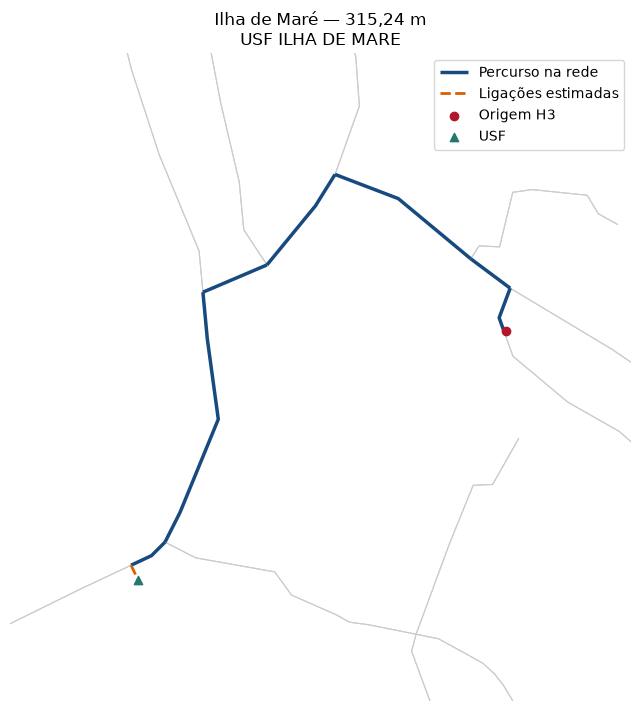

In [84]:
candidatas_mapa = unidades_busca.loc[
    unidades_busca["unidade"].isin(nomes)
    & unidades_busca["aresta_rede"].map(lambda aresta: no_chegada in aresta[:2])
]

assert len(candidatas_mapa) == 1, "Confira se há empate ou mais de um registro de destino."
destino = candidatas_mapa.iloc[0]

def trecho_ate_no(registro, no):
    linha = arestas_mapa.loc[registro["aresta_rede"], "geometry"]
    posicao = linha.project(registro.geometry)
    entrada = linha.interpolate(posicao)

    ponto_no = Point(rede_utm.nodes[no]["x"], rede_utm.nodes[no]["y"])
    extremo = (
        0 if Point(linha.coords[0]).distance(ponto_no)
        <= Point(linha.coords[-1]).distance(ponto_no)
        else linha.length
    )
    return entrada, substring(linha, posicao, extremo)

entrada, trecho_inicial = trecho_ate_no(celula, no_saida)
saida, trecho_final = trecho_ate_no(destino, no_chegada)

trechos = [trecho_inicial]
for a, b in zip(nos_rota, nos_rota[1:]):
    chave = min(rede_utm[a][b], key=lambda k: rede_utm[a][b][k]["length"])
    trechos.append(arestas_mapa.loc[(a, b, chave), "geometry"])
trechos.append(trecho_final)

percurso = gpd.GeoSeries(trechos, crs=arestas_mapa.crs)
ligacoes = gpd.GeoSeries([
    LineString([celula.geometry, entrada]),
    LineString([saida, destino.geometry]),
], crs=arestas_mapa.crs)

xmin, ymin, xmax, ymax = ligacoes.total_bounds
rxmin, rymin, rxmax, rymax = percurso.total_bounds
xmin, ymin = min(xmin, rxmin) - 50, min(ymin, rymin) - 50
xmax, ymax = max(xmax, rxmax) + 50, max(ymax, rymax) + 50

# caso_atual = amostra_rotas.loc[
#     amostra_rotas["h3_id"].eq(h3_teste), "caso"
# ].iloc[0]

rotulo = amostra_rotas.loc[amostra_rotas["h3_id"].eq(h3_teste), "caso"]
caso_atual = "Ilha de Maré" if rotulo.empty else rotulo.iloc[0]
distancia_texto = f"{celula['dist_final_m']:.2f}".replace(".", ",")

fig, ax = plt.subplots(figsize=(8, 7), layout="constrained")
arestas_mapa.cx[xmin:xmax, ymin:ymax].plot(ax=ax, color="#cccccc", linewidth=0.8)
percurso.plot(ax=ax, color="#174A7E", linewidth=2.5, label="Percurso na rede")
ligacoes.plot(ax=ax, color="#D95F02", linestyle="--", linewidth=2, label="Ligações estimadas")
ax.scatter(celula.geometry.x, celula.geometry.y, color="#B2182B", label="Origem H3", zorder=5)
ax.scatter(
    destino.geometry.x, destino.geometry.y,
    color="#26776E", marker="^", label=destino["tipo_tratado"], zorder=5,
)
ax.set(
    xlim=(xmin, xmax),
    ylim=(ymin, ymax),
    title=f"{caso_atual} — {distancia_texto} m\n{destino['unidade']}",
)
ax.legend()
ax.set_axis_off()
plt.show()

In [85]:
# Nós a partir dos quais uma aresta de escadaria pode ser o
# primeiro trecho de um caminho mínimo até uma UBS ou USF.
nos_antes_de_escada = set()

for u, v, dados in rede_utm.edges(data=True):
    if dados.get("highway") != "steps":
        continue

    if u not in dist_no_ate_unidade_m or v not in dist_no_ate_unidade_m:
        continue

    if np.isclose(
        dist_no_ate_unidade_m[u],
        dados["length"] + dist_no_ate_unidade_m[v],
        atol=0.001,
        rtol=0,
    ):
        nos_antes_de_escada.add(u)


def sai_por_no_de_escada(celula):
    u, v, _ = celula["aresta_rede"]
    via_u = celula["parcial_u_m"] + dist_no_ate_unidade_m.get(u, np.inf)
    via_v = celula["parcial_v_m"] + dist_no_ate_unidade_m.get(v, np.inf)
    no_saida_candidato = u if via_u <= via_v else v
    return no_saida_candidato in nos_antes_de_escada


elegiveis = pontos_grade.loc[
    pontos_grade["pop_estimada"].gt(0)
    & pontos_grade["dist_via_extremidades_m"].notna()
    & pontos_grade["dist_final_m"].eq(pontos_grade["dist_via_extremidades_m"])
]

candidatas_escada = elegiveis.loc[
    elegiveis.apply(sai_por_no_de_escada, axis=1)
].nlargest(5, "pop_estimada")

print(candidatas_escada[["h3_id", "dist_final_m", "pop_estimada"]].round(2).to_string(index=False))

          h3_id  dist_final_m  pop_estimada
8a8116b0ea57fff         58.37        751.07
8a8116a3194ffff        488.54        667.59
8a8116a22487fff        182.11        653.64
8a8116b1936ffff        910.68        652.01
8a8116b0a8b7fff        598.61        643.15


In [86]:
escadas_percorridas = []

for a, b in zip(nos_rota, nos_rota[1:]):
    chave = min(rede_utm[a][b], key=lambda k: rede_utm[a][b][k]["length"])
    dados = rede_utm[a][b][chave]

    if dados.get("highway") == "steps":
        escadas_percorridas.append((a, b, chave))
        print(
            f"{(a, b, chave)} | {dados['length']:.2f} m | "
            f"nome={dados.get('name', '—')} | OSM ID={dados.get('osmid', '—')}"
        )

print("Arestas de escadaria percorridas por inteiro:", len(escadas_percorridas))

Arestas de escadaria percorridas por inteiro: 0


In [87]:
unidades_componentes_menores = unidades_busca.loc[
    unidades_busca["componente"].ne(1),
    ["componente", "unidade", "bairro", "geometry"],
].to_crs(epsg=4326).copy()

unidades_componentes_menores["latitude"] = unidades_componentes_menores.geometry.y
unidades_componentes_menores["longitude"] = unidades_componentes_menores.geometry.x

print(
    unidades_componentes_menores.drop(columns="geometry")
    .sort_values("componente")
    .round({"latitude": 6, "longitude": 6})
    .to_string(index=False)
)

 componente                  unidade                                bairro   latitude  longitude
          4         USF ILHA DE MARE                          ILHA DE MARÉ -12.780375 -38.531678
          5             USF PARAMANA ILHA DOS FRADES/ILHA DE SANTO ANTÔNIO -12.772641 -38.620230
          6 USF BOM JESUS DOS PASSOS          ILHA DE BOM JESUS DOS PASSOS -12.759994 -38.644361


In [88]:
amostra_ilha = (
    pontos_grade.loc[
        pontos_grade["componente"].eq(4)
        & pontos_grade["pop_estimada"].gt(0)
        & pontos_grade["dist_final_m"].notna()
        & pontos_grade["dist_final_m"].eq(
            pontos_grade["dist_via_extremidades_m"]
        )
    ]
    .sort_values(["pop_estimada", "h3_id"], ascending=[False, True])
    .head(1)
)

print(
    amostra_ilha[["h3_id", "dist_final_m", "pop_estimada", "ligacao_m"]]
    .round(2)
    .to_string(index=False)
)

          h3_id  dist_final_m  pop_estimada  ligacao_m
8a8116ae5a37fff        315.24        106.48       0.69


In [89]:
sem_rota_pop = pontos_grade.loc[
    pontos_grade["dist_final_m"].isna()
    & pontos_grade["pop_estimada"].gt(0)
]

caso_pop = sem_rota_pop.nlargest(1, "pop_estimada")
componente_pop = caso_pop["componente"].iloc[0]

caso_ligacao = sem_rota_pop.loc[
    sem_rota_pop["componente"].ne(componente_pop)
].nlargest(1, "ligacao_m")

amostra_sem_rota = pd.concat([
    caso_pop.assign(caso="Maior população estimada sem rota"),
    caso_ligacao.assign(caso="Ligação mais longa em outro componente"),
], ignore_index=True)

unidades_por_componente = unidades_busca["componente"].value_counts()
amostra_sem_rota["unidades_no_componente"] = (
    amostra_sem_rota["componente"].map(unidades_por_componente).fillna(0).astype(int)
)
amostra_sem_rota["extremidades_com_rota"] = amostra_sem_rota["aresta_rede"].map(
    lambda aresta: len(set(aresta[:2]).intersection(dist_no_ate_unidade_m))
)

print(amostra_sem_rota[[
    "caso", "h3_id", "pop_estimada", "ligacao_m", "componente",
    "unidades_no_componente", "extremidades_com_rota",
]].round(2).to_string(index=False))

                                  caso           h3_id  pop_estimada  ligacao_m  componente  unidades_no_componente  extremidades_com_rota
     Maior população estimada sem rota 8a8116b1da57fff        601.71       1.18          23                       0                      0
Ligação mais longa em outro componente 8a8116a41a37fff          0.00    1505.31          72                       0                      0


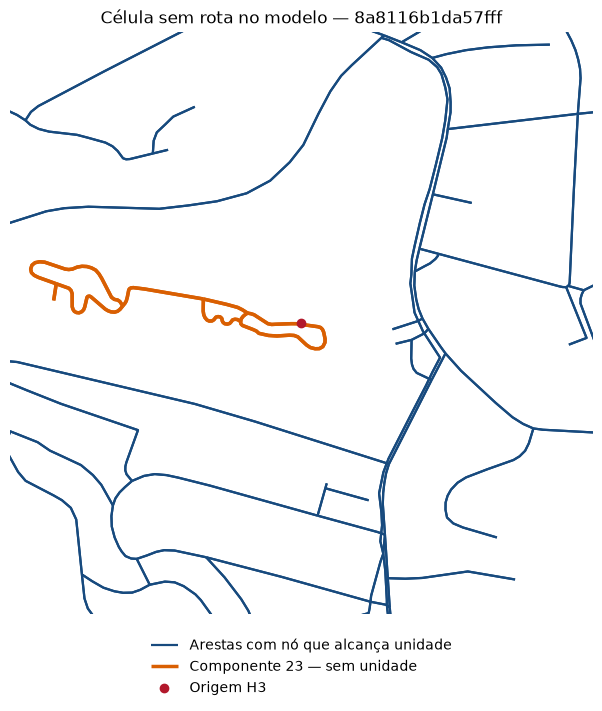

In [90]:
caso = amostra_sem_rota.loc[
    amostra_sem_rota["h3_id"].eq("8a8116b1da57fff")
].iloc[0]

origem = caso.geometry
xmin, ymin, xmax, ymax = origem.buffer(250).bounds
entorno = arestas_mapa.cx[xmin:xmax, ymin:ymax].copy()

entorno["componente"] = [
    componente_por_no[u] for u, v, chave in entorno.index
]

mesmo_componente = entorno["componente"].eq(caso["componente"])
com_rota = np.array([
    u in dist_no_ate_unidade_m or v in dist_no_ate_unidade_m
    for u, v, chave in entorno.index
])

fig, ax = plt.subplots(figsize=(8, 7), layout="constrained")
entorno.plot(ax=ax, color="#cccccc", linewidth=0.9)

if com_rota.any():
    entorno.loc[com_rota].plot(
        ax=ax, color="#174A7E", linewidth=1.6, label="Arestas com nó que alcança unidade"
    )

entorno.loc[mesmo_componente].plot(
    ax=ax, color="#D95F02", linewidth=2.5, label="Componente 23 — sem unidade"
)

ax.scatter(origem.x, origem.y, color="#B2182B", label="Origem H3", zorder=5)
ax.set(
    xlim=(xmin, xmax), ylim=(ymin, ymax),
    title=f"Célula sem rota no modelo — {caso['h3_id']}",
)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.02), frameon=False)
ax.set_axis_off()
plt.show()

In [91]:
dentro = unidades_busca.geometry.intersects(limite_salvador)

print("Unidades usadas no roteamento:", len(unidades_busca))
print("\nContagem por tipo:")
print(unidades_busca["tipo_tratado"].value_counts().to_string())

print("\nUnidades dentro ou no limite do recorte:", dentro.sum())
print("Unidades fora do recorte:", (~dentro).sum())

if (~dentro).any():
    print(
        unidades_busca.loc[~dentro, ["unidade", "tipo_tratado", "bairro"]]
        .to_string(index=False)
    )

Unidades usadas no roteamento: 142

Contagem por tipo:
tipo_tratado
USF    97
UBS    45

Unidades dentro ou no limite do recorte: 142
Unidades fora do recorte: 0


In [92]:
def normalizar_texto(coluna):
    return (
        coluna.astype("string")
        .fillna("")
        .str.normalize("NFKD")
        .str.replace(r"[\u0300-\u036f]", "", regex=True)
        .str.upper()
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )

auditoria_unidades = unidades_busca.copy()
campos = ["logradouro", "numero", "bairro"]
endereco = auditoria_unidades[campos].apply(normalizar_texto)

# Evita tratar duas unidades na mesma rua, ambas sem número,
# como se estivessem necessariamente no mesmo endereço.
endereco_completo = endereco.ne("").all(axis=1) & ~endereco["numero"].isin(
    ["S/N", "S / N", "SN", "SEM NÚMERO", "SEM NUMERO"]
)

mesmo_endereco = endereco_completo & endereco.duplicated(keep=False)
mesmo_ponto = auditoria_unidades.geometry.to_wkb().duplicated(keep=False)

print("Registros com endereço apto à comparação:", endereco_completo.sum())
print("Registros em endereços repetidos:", mesmo_endereco.sum())
print("Registros com coordenadas idênticas:", mesmo_ponto.sum())

if (mesmo_endereco | mesmo_ponto).any():
    print(
        auditoria_unidades.loc[
            mesmo_endereco | mesmo_ponto,
            ["unidade", "tipo_tratado", "logradouro", "numero", "complement", "bairro"],
        ].sort_values(["bairro", "logradouro", "numero"]).to_string(index=False)
    )

Registros com endereço apto à comparação: 35
Registros em endereços repetidos: 0
Registros com coordenadas idênticas: 0


Base de unidades de saúde. Foi usada a camada sau_p do GeoPackage Unidades de Saúde, do portal Salvador Dados, sob responsabilidade da Fundação Mário Leal Ferreira (FMLF). Os metadados são de 25/03/2021, e a publicação informada é de 07/04/2021. A classificação foi padronizada removendo espaços e quebras de linha e convertendo os valores para maiúsculas. Foram mantidos apenas os registros classificados como UBS ou USF. O roteamento usou 45 UBS e 97 USF, todas dentro ou sobre o limite do recorte. Não houve coordenadas idênticas nem endereços repetidos entre os 35 registros comparáveis. O funcionamento atual das unidades não foi verificado; as distâncias se referem aos pontos da base utilizada.

In [93]:

pasta_tabelas = Path("../resultados/tabelas")
formato_csv = {"sep": ";", "decimal": ",", "encoding": "utf-8-sig"}

base = pd.read_csv(
    pasta_tabelas / "indicadores_por_prefeitura_bairro.csv",
    dtype={"COD_PBR": "string"},
    **formato_csv,
).rename(columns={"renda_media_rs": "rendimento_setorial_ponderado_rs"})

# Converte as cinco faixas em colunas de população e percentual.
sufixos = dict(zip(
    ordem_faixas,
    ["ate_500m", "500m_a_1km", "1km_a_1333m", "acima_1333m", "sem_rota"],
))

faixas_largas = faixas_pb.pivot(
    index="COD_PBR",
    columns="faixa_distancia",
    values=["pop_estimada_pb", "pct_pop"],
)

prefixos = {"pop_estimada_pb": "pop", "pct_pop": "pct"}
faixas_largas.columns = [
    f"{prefixos[medida]}_{sufixos[faixa]}"
    for medida, faixa in faixas_largas.columns
]

metricas = [
    "media_ponderada_m", "mediana_ponderada_m", "p75_ponderado_m",
    "p90_ponderado_m", "maior_distancia_com_rota_m",
]

consolidado = (
    base.merge(
        resumo_dist_pb[["COD_PBR", *metricas]],
        on="COD_PBR", how="left", validate="one_to_one",
    )
    .merge(
        faixas_largas.reset_index(),
        on="COD_PBR", how="left", validate="one_to_one",
    )
    .sort_values("mediana_ponderada_m")
)

colunas_faixas = faixas_largas.columns.tolist()
colunas_pct = [f"pct_{sufixo}" for sufixo in sufixos.values()]
pct_ate_1333m = consolidado[
    ["pct_ate_500m", "pct_500m_a_1km", "pct_1km_a_1333m"]
].sum(axis=1)

assert len(consolidado) == 10, "Confira o número de regiões."
assert consolidado[metricas + colunas_faixas].notna().all().all(), "Faltam indicadores."
assert np.allclose(consolidado[colunas_pct].sum(axis=1), 100, atol=0.01, rtol=0)
assert np.allclose(pct_ate_1333m, consolidado["pct_ate_20"], atol=0.01, rtol=0)

saida = pasta_tabelas / "indicadores_por_prefeitura_bairro_revisado.csv"
consolidado.to_csv(saida, index=False, **formato_csv)

print("Regiões:", len(consolidado))
print("Arquivo salvo em:", saida.resolve())
print(consolidado[["COD_PBR", "mediana_ponderada_m", "pct_sem_rota"]]
      .round(2).to_string(index=False))

Regiões: 10
Arquivo salvo em: /home/emanu/projetos/ftl-projeto-final/resultados/tabelas/indicadores_por_prefeitura_bairro_revisado.csv
COD_PBR  mediana_ponderada_m  pct_sem_rota
     II               627.82          0.01
    VII               642.60          0.19
   VIII               688.40          0.35
      I               774.80          0.85
      V               786.37          0.02
     IX               797.67          0.68
    III               869.31          0.56
      X               958.60          1.28
     IV              1076.12          0.96
     VI              1081.82          0.26


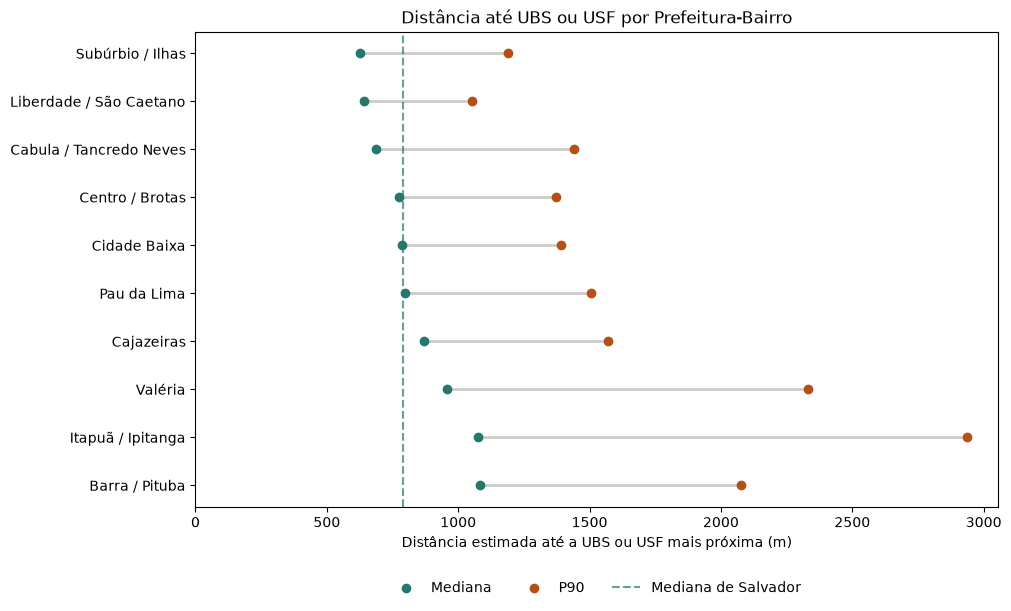

In [94]:
# Exporta as cinco faixas municipais, incluindo "Sem rota no modelo".
faixas_salvador.reset_index().to_csv(
    pasta_tabelas / "faixas_distancia_salvador.csv",
    index=False,
    **formato_csv,
)

dados = consolidado.sort_values("mediana_ponderada_m").reset_index(drop=True)
nomes = dados["PREF_BAIRR"].str.split(" - ", n=1).str[-1].str.strip()
y = np.arange(len(dados))

fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")

ax.hlines(
    y, dados["mediana_ponderada_m"], dados["p90_ponderado_m"],
    color="#cccccc", linewidth=2,
)
ax.scatter(dados["mediana_ponderada_m"], y, color="#26776e", label="Mediana", zorder=3)
ax.scatter(dados["p90_ponderado_m"], y, color="#b35116", label="P90", zorder=3)
ax.axvline(
    resumo_dist_salvador["mediana_ponderada_m"],
    color="#26776e", linestyle="--", alpha=0.7,
    label="Mediana de Salvador",
)

ax.set_yticks(y, nomes)
ax.invert_yaxis()
ax.set_xlim(left=0)
ax.set_xlabel("Distância estimada até a UBS ou USF mais próxima (m)")
ax.set_title("Distância até UBS ou USF por Prefeitura-Bairro")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=3, frameon=False)

saida_grafico = Path("../resultados/graficos/distancia_ubs_usf_por_prefeitura_bairro.png")
saida_grafico.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(saida_grafico, dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

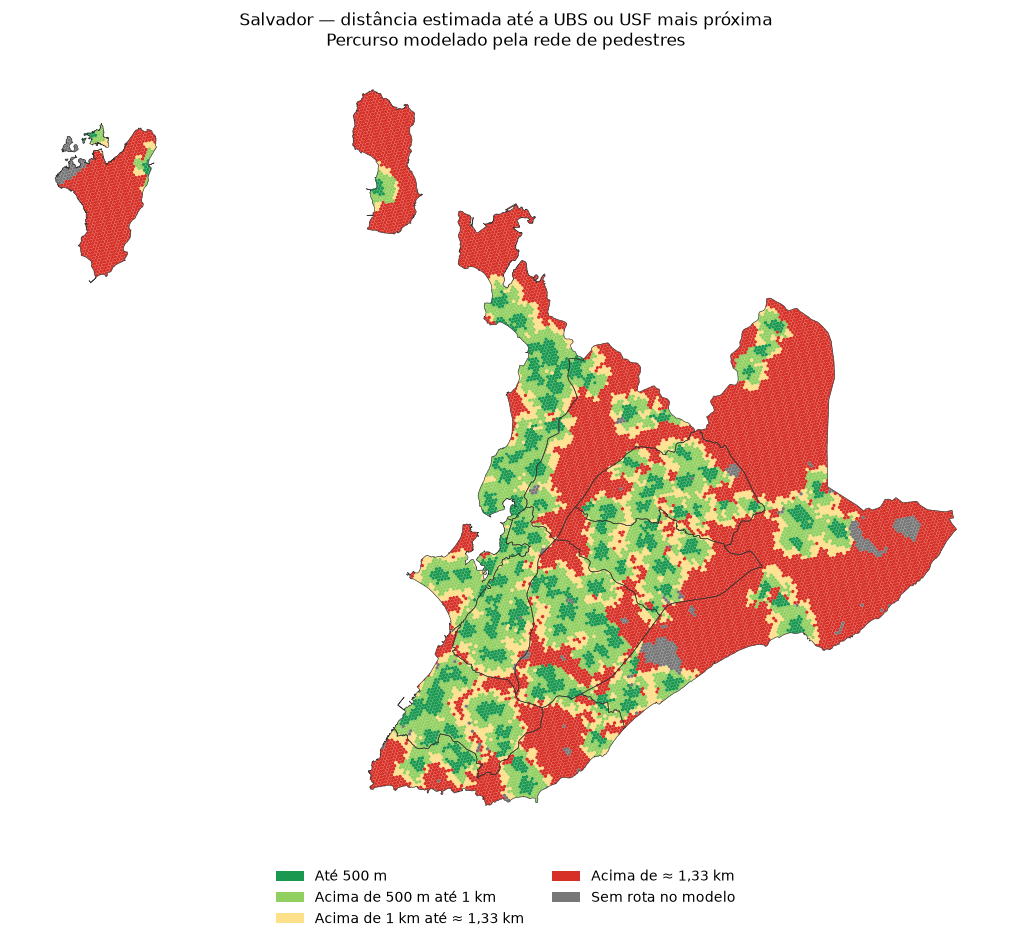

In [95]:
mapa_distancia = grade_poligonos.merge(
    grade_distancia[["h3_id", "faixa_distancia"]],
    on="h3_id",
    how="left",
    validate="one_to_one",
)

assert len(mapa_distancia) == 18_317
assert mapa_distancia["faixa_distancia"].notna().all()

cores = dict(zip(
    ordem_faixas,
    ["#1a9850", "#91cf60", "#fee08b", "#d73027", "#777777"],
))

fig, ax = plt.subplots(figsize=(10, 11), layout="constrained")
mapa_distancia.plot(
    ax=ax,
    color=mapa_distancia["faixa_distancia"].map(cores),
    linewidth=0,
)
pref_bairro.to_crs(mapa_distancia.crs).boundary.plot(
    ax=ax, color="#333333", linewidth=0.45
)

ax.set_title(
    "Salvador — distância estimada até a UBS ou USF mais próxima\n"
    "Percurso modelado pela rede de pedestres"
)
ax.legend(
    handles=[Patch(facecolor=cor, label=faixa) for faixa, cor in cores.items()],
    loc="upper center",
    bbox_to_anchor=(0.5, -0.02),
    ncol=2,
    frameon=False,
)
ax.set_axis_off()

saida_mapa = Path("../resultados/mapas/distancia_ubs_usf_salvador.png")
saida_mapa.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(saida_mapa, dpi=200, bbox_inches="tight", facecolor="white")
plt.show()